In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, LassoCV, RidgeCV, ElasticNetCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import roc_curve, roc_auc_score


warnings.filterwarnings('ignore')

In [2]:
df = sns.load_dataset("titanic")

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
df.shape

(891, 15)

In [6]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [7]:
def clean(df):
    threshold = 0.6
    # 
    df = df.loc[:, df.isnull().mean() < threshold]
    return df

df = clean(df)    

In [8]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
embark_town      2
alive            0
alone            0
dtype: int64

In [9]:
def impute(df):
    # Empty values for age replaced with median.
    df["age"] = df["age"].fillna(df["age"].median())
    # Empty values for embarked replaced with mod because this column is a categorical values.
    df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
        # And I can replaceing with mod because this column includes a categorical values.
    df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0]) # [0] -> .fillna metodu tek deger istedigi icin.
    return df
    
df = impute(df)    

In [10]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [11]:
df = df.drop("alive", axis=1)

def encoding(df):
    
    df["sex"] = df["sex"].map({"male":1, "female":0})
    
    df["adult_male"] = df["adult_male"].astype(int)
    df["alone"] = df["alone"].astype(int)
    
    df = pd.get_dummies(
        df,
        columns=["embarked", "class", "who", "embark_town"],
        drop_first=True
        )
    df = df.astype(int, errors='ignore')
    return df
    
df = encoding(df)

In [12]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,adult_male,alone,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,embark_town_Queenstown,embark_town_Southampton
0,0,3,1,22,1,0,7,1,0,0,1,0,1,1,0,0,1
1,1,1,0,38,1,0,71,0,0,0,0,0,0,0,1,0,0
2,1,3,0,26,0,0,7,0,1,0,1,0,1,0,1,0,1
3,1,1,0,35,1,0,53,0,0,0,1,0,0,0,1,0,1
4,0,3,1,35,0,0,8,1,1,0,1,0,1,1,0,0,1


In [13]:
df.describe()

,survived,pclass,sex,age,sibsp,parch,fare,adult_male,alone,embarked_Q,embarked_S,class_Second,class_Third,who_man,who_woman,embark_town_Queenstown,embark_town_Southampton
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.647587,29.345679,0.523008,0.381594,31.785634,0.602694,0.602694,0.086420,0.725028,0.206510,0.551066,0.602694,0.304153,0.086420,0.725028
std,0.486592,0.836071,0.477990,13.028212,1.102743,0.806057,49.703730,0.489615,0.489615,0.281141,0.446751,0.405028,0.497665,0.489615,0.460306,0.281141,0.446751
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,0.000000,0.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,3.000000,1.000000,28.000000,0.000000,0.000000,14.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000
75%,1.000000,3.000000,1.000000,35.000000,1.000000,0.000000,31.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000
max,1.000000,3.000000,1.000000,80.000000,8.000000,6.000000,512.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [14]:
df.corr(numeric_only=True)["survived"]

survived                   1.000000
pclass                    -0.338481
sex                       -0.543351
age                       -0.064909
sibsp                     -0.035322
parch                      0.081629
fare                       0.257482
adult_male                -0.557080
alone                     -0.203367
embarked_Q                 0.003650
embarked_S                -0.149683
class_Second               0.093349
class_Third               -0.322308
who_man                   -0.557080
who_woman                  0.506562
embark_town_Queenstown     0.003650
embark_town_Southampton   -0.149683
Name: survived, dtype: float64

In [15]:
X = df.drop("survived", axis=1)
y = df["survived"]

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic = LogisticRegression()
logistic.fit(X_train_scaled, y_train)
y_pred = logistic.predict(X_test_scaled)

In [18]:
Score = accuracy_score(y_pred, y_test)
print("Accuracy Score: ", Score, "\n")
print(classification_report(y_pred, y_test))
print("Confusion Matrix: \n", confusion_matrix(y_pred, y_test))

Accuracy Score:  0.8100558659217877 

              precision    recall  f1-score   support

           0       0.87      0.82      0.84       111
           1       0.73      0.79      0.76        68

    accuracy                           0.81       179
   macro avg       0.80      0.81      0.80       179
weighted avg       0.81      0.81      0.81       179

Confusion Matrix: 
 [[91 20]
 [14 54]]


In [19]:
params = ({
    "penalty" : ["l1", "l2", "elasticnet"], # -> ceza turleri. 
    "C" : [0.1, 1, 10, 100, 1000], # -> verilen cezanin katsayisi.
    "solver" : ["lbfgs", "liblinear", "newton-cg","newton-cholesky", "sag", "saga"],  
    "class_weight" : [{0:w, 1:y} for w in [1,10,50,100] for y in [1,10,50,100]]
})

In [20]:
cv = StratifiedKFold()

grid = GridSearchCV(estimator=logistic, param_grid=params, cv=cv, scoring="accuracy", n_jobs=-1)

grid.fit(X_train, y_train)

/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/yusuf/anaconda3/lib/python3.13/site-packages/sklearn/linear_mode

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
             estimator=LogisticRegression(), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10, 100, 1000],
                         'class_weight': [{0: 1, 1: 1}, {0: 1, 1: 10},
                                          {0: 1, 1: 50}, {0: 1, 1: 100},
                                          {0: 10, 1: 1}, {0: 10, 1: 10},
                                          {0: 10, 1: 50}, {0: 10, 1: 100},
                                          {0: 50, 1: 1}, {0: 50, 1: 10},
                                          {0: 50, 1: 50}, {0: 50, 1: 100},
                                          {0: 100, 1: 1}, {0: 100, 1: 10},
                                          {0: 100, 1: 50}, {0: 100, 1: 100}],
                         'penalty': ['l1', 'l2', 'elasticnet'],
                         'solver': ['lbfgs', 'liblinear', 'newton-cg',
                                    'newton-cholesky', 'sag', 'saga']},
             scoring='accuracy')

In [21]:
grid.best_params_

{'C': 0.1,
 'class_weight': {0: 50, 1: 50},
 'penalty': 'l1',
 'solver': 'liblinear'}

In [22]:
grid.best_score_

np.float64(0.8230079779375554)

In [23]:
y_pred1 = grid.predict(X_test)

In [24]:
Score = accuracy_score(y_pred, y_test)
print("Accuracy Score: ", Score, "\n")
print(classification_report(y_pred, y_test))
print("Confusion Matrix: \n", confusion_matrix(y_pred, y_test))

Accuracy Score:  0.8100558659217877 

              precision    recall  f1-score   support

           0       0.87      0.82      0.84       111
           1       0.73      0.79      0.76        68

    accuracy                           0.81       179
   macro avg       0.80      0.81      0.80       179
weighted avg       0.81      0.81      0.81       179

Confusion Matrix: 
 [[91 20]
 [14 54]]


In [25]:
model_prob = grid.predict_proba(X_test)

model_prob = model_prob[:,1]

In [26]:
model_auc = roc_auc_score(y_test, model_prob)
model_auc

np.float64(0.8751608751608752)

In [27]:
model_fpr, model_tpr, thresholds =  roc_curve(y_test, model_prob)

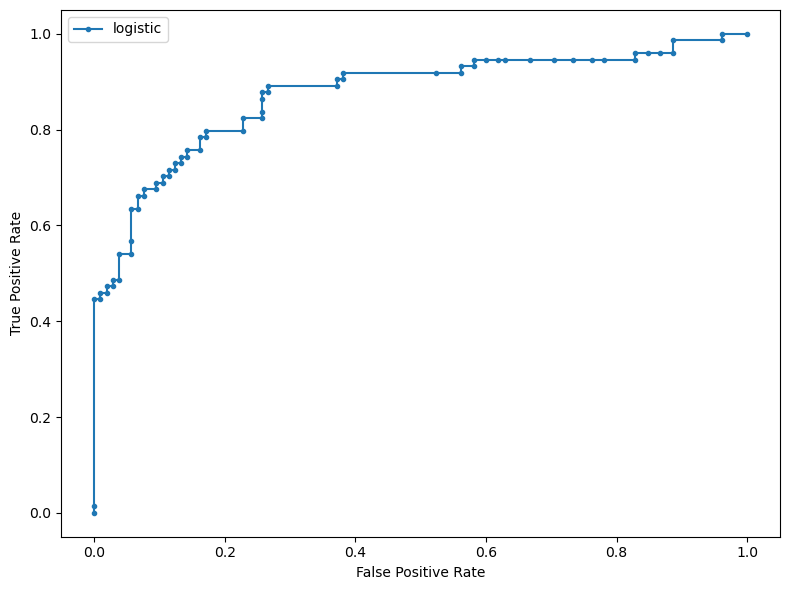

In [28]:
plt.figure(figsize=(8,6))
plt.plot(model_fpr, model_tpr, marker=".", label="logistic")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

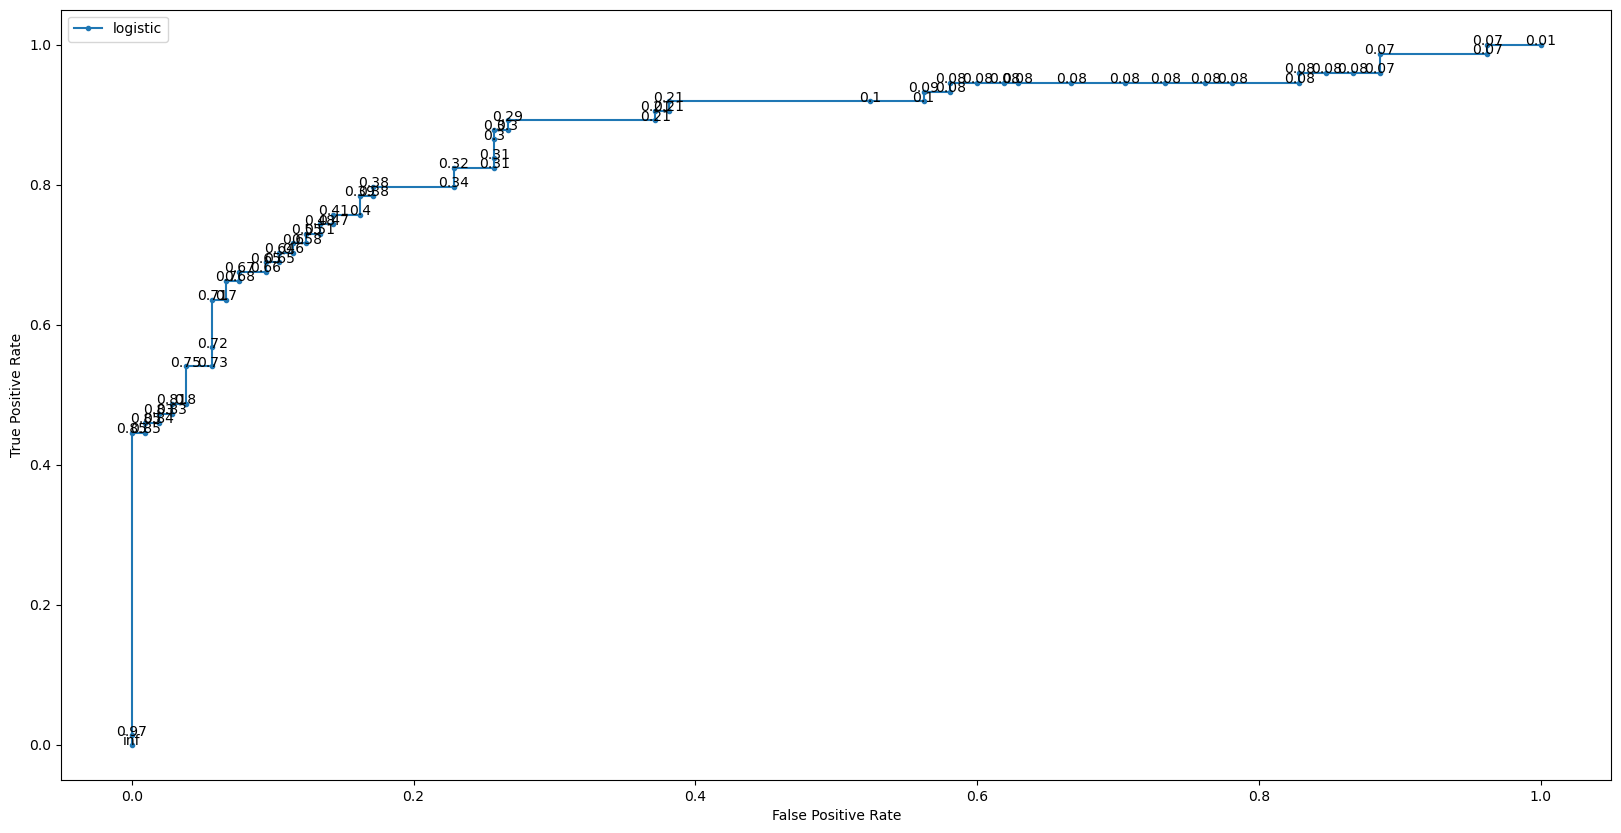

In [29]:
fig, ax = plt.subplots(figsize=(20,10))

ax.plot(model_fpr, model_tpr, marker=".", label="logistic")

for fpr, tpr, thresh in zip(model_fpr, model_tpr, thresholds):
    ax.annotate(f"{np.round(thresh, 2)}", (fpr, tpr), ha="center")
                            # .round(thresh, 2) -> esik degerin 2 basamgini gostermesi icin
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.show()

In [30]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error: ", mse)
print("Mean Absolute Error: ", mae)
print("R2 Score: ", r2)


Mean Squared Error:  0.18994413407821228
Mean Absolute Error:  0.18994413407821228
R2 Score:  0.2167310167310167
